# Manipulating Neuroimages in Python

The primary goal of this workshop is to become familiar with loading, modifying, saving, and visualizing neuroimages in Python. A secondary goal is to develop a conceptual understanding of the data structures involved, to facilitate diagnosing problems in data or analysis pipelines.

To these ends, we'll be exploring two libraries: [nibabel](http://nipy.org/nibabel/) and [nilearn](https://nilearn.github.io/).

Each of these projects has excellent documentation. While this should get you started, it is well worth your time to look through these sites.

In [1]:
from __future__ import print_function

import sys
import os
import numpy as np
import nibabel as nib
import nilearn as nl

import nilearn.plotting
import matplotlib as mpl
import pylab as plt
import seaborn as sns
sns.set_style('white')
%matplotlib inline

# Nibabel

Nibabel is a low-level Python library that gives access to a variety of imaging formats, with a particular focus on providing a common interface to the various volumetric formats produced by scanners and used in common neuroimaging toolkits.

 - NIfTI-1
 - NIfTI-2
 - SPM Analyze
 - FreeSurfer .mgh/.mgz files
 - DICOM
 - Philips PAR/REC
 - Siemens ECAT

It also supports surface file formats

 - GIFTI
 - FreeSurfer surfaces, labels and annotations

Connectivity

 - CIFTI-2 (next release!)

Tractocgraphy

 - TrackViz .trk files

And a number of related formats.

*Almost* all of these can be loaded through the `nibabel.load` interface.

## Loading and inspecting images in nibabel

In [2]:
t1 = nib.load('example/sub-01/anat/sub-01_T1w.nii.gz')
print(t1)

<class 'nibabel.nifti1.Nifti1Image'>
data shape (160, 192, 192)
affine: 
[[   1.            0.            0.          -81.        ]
 [   0.            1.33333302    0.         -133.        ]
 [   0.            0.            1.33333302 -129.        ]
 [   0.            0.            0.            1.        ]]
metadata:
<class 'nibabel.nifti1.Nifti1Header'> object, endian='<'
sizeof_hdr      : 348
data_type       : 
db_name         : 
extents         : 0
session_error   : 0
regular         : r
dim_info        : 0
dim             : [  3 160 192 192   1   1   1   1]
intent_p1       : 0.0
intent_p2       : 0.0
intent_p3       : 0.0
intent_code     : none
datatype        : int16
bitpix          : 16
slice_start     : 0
pixdim          : [ 1.          1.          1.33333302  1.33333302  2.29999995  0.          0.
  0.        ]
vox_offset      : 0.0
scl_slope       : nan
scl_inter       : nan
slice_end       : 0
slice_code      : unknown
xyzt_units      : 10
cal_max         : 0.0
cal_min      

This data-affine-header structure is common to volumetric formats in nibabel, though the details of the header will vary from format to format.

These objects can be accessed through the following interfaces.

In [3]:
data = t1.get_data()
affine = t1.affine
header = t1.header

###### Aside
Why not just `t1.data`? Working with neuroimages can use a lot of memory, so nibabel works hard to be memory efficient. If it can read some data while leaving the rest on disk, it will. `t1.get_data()` reflects that it's doing some work behind the scenes.

### Data

The data object acts like a simple numpy array. It has a shape, it can be sliced and generally manipulated as you would expect.

(160, 192, 192)


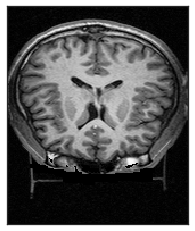

In [4]:
print(data.shape)
fig = plt.imshow(data[:,:,data.shape[2] / 2].T, cmap='Greys_r')
fig.axes.set_xticks([])
_ = fig.axes.set_yticks([])

Nibabel has its own viewer, which can be accessed through `img.orthoview()`. This viewer scales voxels to reflect their size, and labels orientations. From a normal IPython console, it will create an interactive window, and you can click to select different slices, similar to `mricron`.

/opt/conda/envs/python2/lib/python2.7/site-packages/matplotlib/font_manager.py:1297: UserWarning: findfont: Font family [u'sans-serif'] not found. Falling back to DejaVu Sans
  (prop.get_family(), self.defaultFamily[fontext]))
/opt/conda/envs/python2/lib/python2.7/site-packages/matplotlib/axes/_base.py:1292: UnicodeWarning: Unicode equal comparison failed to convert both arguments to Unicode - interpreting them as being unequal
  if aspect == 'normal':
/opt/conda/envs/python2/lib/python2.7/site-packages/matplotlib/axes/_base.py:1297: UnicodeWarning: Unicode equal comparison failed to convert both arguments to Unicode - interpreting them as being unequal
  elif aspect in ('equal', 'auto'):


<OrthoSlicer3D: example/sub-01/anat/sub-01_T1w.nii.gz (160, 192, 192)>

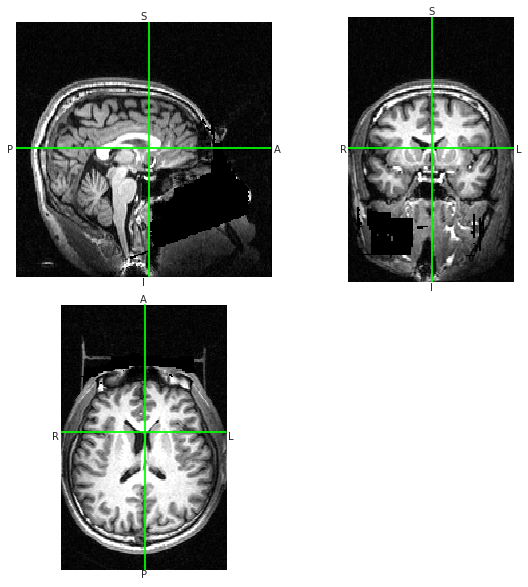

In [5]:
t1.orthoview()

###### Quirk

 - `img.get_data_dtype()` shows the type of the data on disk
 - `img.get_data().dtype` shows the type of the data that you're working with

These are not always the same, and not being clear on this [has caused problems](https://github.com/nipy/nibabel/issues/490). Further, modifying one does not update the other. This is especially important to keep in mind later, when saving files.

In [6]:
print((data.dtype, t1.get_data_dtype()))

(dtype('<i2'), dtype('<i2'))


### Affine

The affine is a 4 x 4 numpy array. This describes the transformation from the voxel space (indices [i, j, k]) to the reference space (distance in mm (x, y, z)).

It can be used, for instance, to discover the voxel that contains the origin of the image:

In [7]:
x, y, z, _ = np.linalg.pinv(affine).dot(np.array([0, 0, 0, 1])).astype(int)

print("Affine:")
print(affine)
print
print("Center: ({:d}, {:d}, {:d})".format(x, y, z))

Affine:
[[   1.            0.            0.          -81.        ]
 [   0.            1.33333302    0.         -133.        ]
 [   0.            0.            1.33333302 -129.        ]
 [   0.            0.            0.            1.        ]]
Center: (81, 99, 96)


The affine also encodes the axis orientation and voxel sizes:

In [8]:
nib.aff2axcodes(affine)

('R', 'A', 'S')

In [9]:
nib.affines.voxel_sizes(affine)

array([ 1.        ,  1.33333302,  1.33333302])

### Header

The header is a nibabel structure that stores all of the metadata of the image. You can query it directly, if necessary:

In [10]:
print(header)
print
header.structarr['descrip']

<class 'nibabel.nifti1.Nifti1Header'> object, endian='<'
sizeof_hdr      : 348
data_type       : 
db_name         : 
extents         : 0
session_error   : 0
regular         : r
dim_info        : 0
dim             : [  3 160 192 192   1   1   1   1]
intent_p1       : 0.0
intent_p2       : 0.0
intent_p3       : 0.0
intent_code     : none
datatype        : int16
bitpix          : 16
slice_start     : 0
pixdim          : [ 1.          1.          1.33333302  1.33333302  2.29999995  0.          0.
  0.        ]
vox_offset      : 0.0
scl_slope       : nan
scl_inter       : nan
slice_end       : 0
slice_code      : unknown
xyzt_units      : 10
cal_max         : 0.0
cal_min         : 0.0
slice_duration  : 0.0
toffset         : 0.0
glmax           : 0
glmin           : 0
descrip         : FSL5.0
aux_file        : 
qform_code      : scanner
sform_code      : scanner
quatern_b       : 0.0
quatern_c       : 0.0
quatern_d       : 0.0
qoffset_x       : -81.0
qoffset_y       : -133.0
qoffset_z       

array('FSL5.0', 
      dtype='|S80')

But it also provides interfaces for the more common information.

In [11]:
for method in ('get_zooms', 'get_xyzt_units', 'get_qform', 'get_sform'):
    print("header.{}()".format(method))
    print(getattr(header, method)())
    print

header.get_zooms()
(1.0, 1.333333, 1.333333)
header.get_xyzt_units()
('mm', 'sec')
header.get_qform()
[[   1.            0.            0.          -81.        ]
 [   0.            1.33333302    0.         -133.        ]
 [   0.            0.            1.33333302 -129.        ]
 [   0.            0.            0.            1.        ]]
header.get_sform()
[[   1.            0.            0.          -81.        ]
 [   0.            1.33333302    0.         -133.        ]
 [   0.            0.            1.33333302 -129.        ]
 [   0.            0.            0.            1.        ]]


Normally, we're not particularly interested in the header or the affine. But it's important to know they're there, and, especially, to remember to copy them when making new images, so that derivatives stay aligned with the original image.

## nib-ls

Nibabel comes packaged with a command-line tool to print common metadata about any (volumetric) neuroimaging format nibabel supports. By default, it shows (on-disk) data type, dimensions and voxel sizes. We can also inspect header fields by name, for instance, `descrip`:

In [12]:
!nib-ls -H descrip example/sub-01/anat/sub-01_T1w.nii.gz

example/sub-01/anat/sub-01_T1w.nii.gz int16 [160, 192, 192] 1.00x1.33x1.33   FSL5.0



## Creating and saving images

Suppose we want to save space by rescaling our image to a smaller datatype, such as an unsigned byte. To do this, we create a new image with a modified data array, and copy over the old affine and header. We then use the `img.to_filename()` method to save.

In [13]:
rescaled = ((data - data.min()) * 255. / (data.max() - data.min())).astype(np.uint8)
rescaled_img = nib.Nifti1Image(rescaled, affine=affine, header=header.copy())

print((rescaled_img.get_data().dtype, rescaled_img.get_data_dtype()))

(dtype('uint8'), dtype('<i2'))


Our data array has the correct type, but the on-disk format is determined by the header, so saving now will not do what we want.

In [14]:
rescaled_img.to_filename('rescaled1.nii.gz')
test = nib.load('rescaled1.nii.gz')
print((test.get_data().dtype, test.get_data_dtype()))

(dtype('<i2'), dtype('<i2'))


Instead, we need to set the data type in the header using `img.set_data_dtype()`:

In [15]:
rescaled_img.set_data_dtype(np.uint8)
rescaled_img.to_filename('rescaled2.nii.gz')
test = nib.load('rescaled2.nii.gz')
print((test.get_data().dtype, test.get_data_dtype()))

# Check that our data is what we think it is
assert np.array_equal(test.get_data(), rescaled)

(dtype('uint8'), dtype('uint8'))


###### Aside

There are other ways to save images. The advantage to `img.to_filename()` is that, if your file extension doesn't match the image type, it won't try anything fancy; it will just fail. In my experience, a mismatch of image and file extension is much more likely to be an error than what you intended.

## Functional time series

We've explored much of nibabel's functionality (at least for NIfTI-1 images). Let's take what we've learned to look at an fMRI series and create a mean volume that could be used for alignment.

First we'll `nib-ls` the file:

In [16]:
!nib-ls example/sub-01/func/sub-01_task-mixedgamblestask_run-01_bold.nii.gz

example/sub-01/func/sub-01_task-mixedgamblestask_run-01_bold.nii.gz int16 [ 64,  64,  34, 240] 3.12x3.12x4.00x2.00



We see that this is a 4-dimensional dataset with 240 volumes, collected at a TR of 2s. We will confirm this when we load the file, and also see that the data is LAS oriented.

In [17]:
epi = nib.load('example/sub-01/func/sub-01_task-mixedgamblestask_run-01_bold.nii.gz')
print(epi.get_data_dtype())
print(epi.shape)
print(epi.header.get_zooms())
print(epi.header.get_xyzt_units())
print(nib.aff2axcodes(epi.affine))

int16
(64, 64, 34, 240)
(3.125, 3.125, 4.0, 2.0)
('mm', 'sec')
('L', 'A', 'S')


For 4D images, `img.orthoview()` also shows the time series at the voxel in focus:

<OrthoSlicer3D: example/sub-01/func/sub-01_task-mixedgamblestask_run-01_bold.nii.gz (64, 64, 34, 240)>

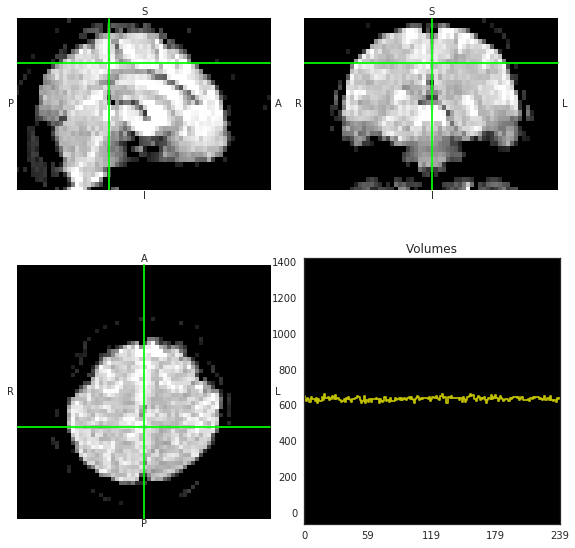

In [18]:
epi.orthoview()

Remembering that the data object is just a numpy array, we can easily take the mean over time:

In [19]:
mean_data = epi.get_data().mean(axis=3)
mean_data.shape

(64, 64, 34)

<OrthoSlicer3D: (64, 64, 34)>

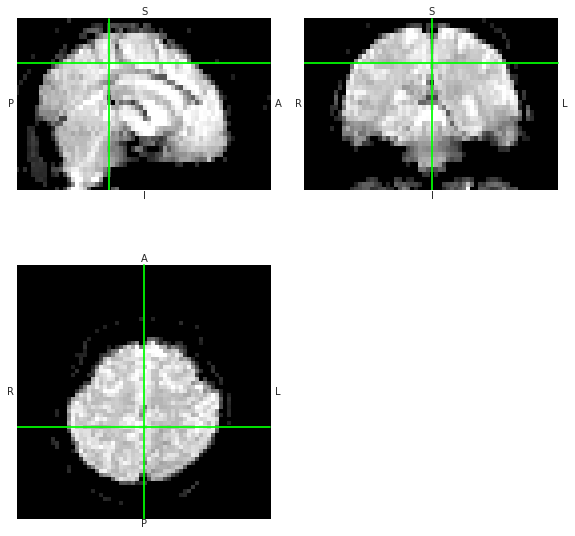

In [20]:
mean_epi = nib.Nifti1Image(mean_data, affine=epi.affine, header=epi.header.copy())
mean_epi.orthoview()

Looks how we'd expect. Let's save it!

In [21]:
mean_epi.to_filename('mean_epi.nii.gz')

# Nilearn

Nilearn is a library which makes visualizing neuroimages and exposing them to machine learning algorithms straightforward. It also simplifies common tasks.

For example, we can recreate the mean EPI image we just made in one line:

In [22]:
img = nl.image.mean_img('example/sub-01/func/sub-01_task-mixedgamblestask_run-01_bold.nii.gz')
print(img)

<class 'nibabel.nifti1.Nifti1Image'>
data shape (64, 64, 34)
affine: 
[[  -3.125    0.       0.     101.   ]
 [   0.       3.125    0.     -72.   ]
 [   0.       0.       4.     -99.   ]
 [   0.       0.       0.       1.   ]]
metadata:
<class 'nibabel.nifti1.Nifti1Header'> object, endian='<'
sizeof_hdr      : 348
data_type       : 
db_name         : 
extents         : 0
session_error   : 0
regular         : 
dim_info        : 0
dim             : [ 3 64 64 34  1  1  1  1]
intent_p1       : 0.0
intent_p2       : 0.0
intent_p3       : 0.0
intent_code     : none
datatype        : float64
bitpix          : 64
slice_start     : 0
pixdim          : [-1.     3.125  3.125  4.     1.     1.     1.     1.   ]
vox_offset      : 0.0
scl_slope       : nan
scl_inter       : nan
slice_end       : 0
slice_code      : unknown
xyzt_units      : 0
cal_max         : 0.0
cal_min         : 0.0
slice_duration  : 0.0
toffset         : 0.0
glmax           : 0
glmin           : 0
descrip         : 
aux_file    

Nilearn images are just nibabel images! But notice that we didn't have to copy the affine or header. Nilearn does its best to keep your data and metadata together.

Let's verify that we got the same image.

In [23]:
np.array_equal(mean_epi.get_data(), img.get_data())

True

In [24]:
np.array_equal(mean_epi.affine, img.affine)

True

## Plotting images

Nilearn has a variety of plotting facilities. `plot_epi` shows functional images in a high-contrast color scheme.

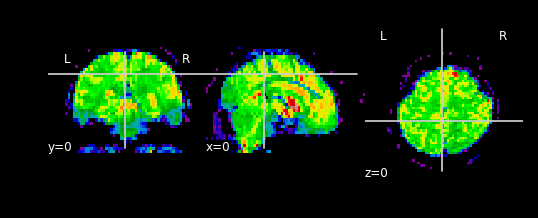

In [25]:
nl.plotting.plot_epi(mean_epi, cut_coords=(0, 0, 0))

We can also plot anatomical images. Let's show the FreeSurfer `aseg` segmentation over the T1 image we loaded earlier:

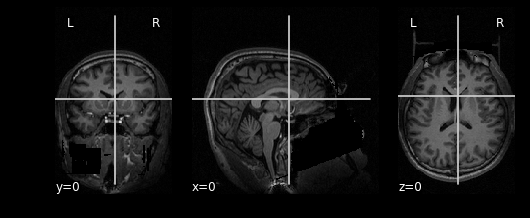

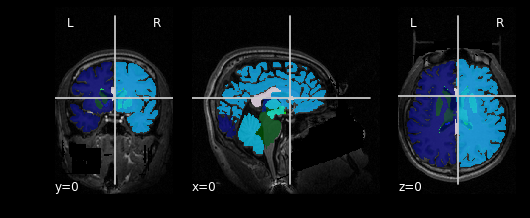

In [26]:
nl.plotting.plot_anat(t1, dim=-1, cut_coords=(0, 0, 0))
nl.plotting.plot_roi('example/derivatives/freesurfer/sub-01/mri/aseg.mgz', t1,
                     dim=-1, cut_coords=(0, 0, 0))

## Plotting surfaces

Nilearn has recently added surface plotting to its repertoire. Let's examine the gray/white boundary and pial surfaces.

In [27]:
white = 'example/derivatives/freesurfer/sub-01/surf/lh.white'
pial = 'example/derivatives/freesurfer/sub-01/surf/lh.pial'
sulc = 'example/derivatives/freesurfer/sub-01/surf/lh.sulc'

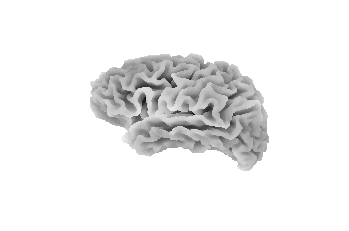

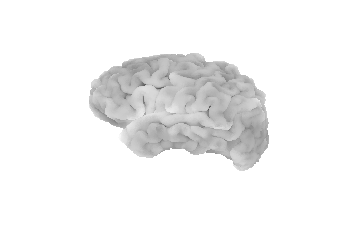

In [28]:
_ = nl.plotting.plot_surf(white, bg_map=sulc)
_ = nl.plotting.plot_surf(pial, bg_map=sulc)

A common step in surface pipelines is to create a surface halfway between the white and pial surface (often called the "midthickness" or "graymid" surface). The fastest, easiest, possibly wrong (but in practice fine) way to get this surface is to take the mean of the coordinates of the corresponding vertices on the white and pial surface. We can do this straightforwardly in nibabel.

In [29]:
wcoords, wfaces, wmeta = nib.freesurfer.read_geometry(white, read_metadata=True)
pcoords, pfaces = nib.freesurfer.read_geometry(white, read_metadata=False)

# Make sure these surfaces actually do correspond
assert np.array_equal(wfaces, pfaces)

(wcoords, wfaces, wmeta)

(array([[ -9.23022747, -94.5045929 , -29.81736946],
        [ -9.67636395, -94.27688599, -29.71606445],
        [-10.01508617, -94.16847229, -29.73501587],
        ..., 
        [ -5.29573536,  47.37877655,  11.16182899],
        [ -6.40319872,  47.88181305,  10.40944767],
        [ -5.65245199,  48.23812103,  11.09020329]]),
 array([[     0,      1,      3],
        [     4,      3,      1],
        [     0,     37,     38],
        ..., 
        [125265, 125437, 125436],
        [125058, 125273, 125289],
        [125028, 125435, 125257]], dtype=int32),
 OrderedDict([('head', array([ 2,  0, 20], dtype=int32)),
              ('valid', u'1  # volume info valid'),
              ('filename', u'../mri/filled-pretess255.mgz'),
              ('volume', array([256, 256, 256])),
              ('voxelsize', array([ 1.,  1.,  1.])),
              ('xras', array([-0.99999994,  0.        ,  0.        ])),
              ('yras', array([ 0.        ,  0.        , -0.99999994])),
              ('zras'

Notice that this is not an image object, just a tuple of coordinates, faces, and an optional metadata dictionary. And it's an example of a file nibabel doesn't handle with `nibabel.load()`.

Coordinates are the (x, y, z) coordinates of each vertex; faces are a triangle composed of three vertices, and the metadata describes the provenance and alignment.

In [30]:
gcoords = (wcoords + pcoords) / 2
# nilearn can be pretty picky about names, so fool it into reading this as a surface file
nib.freesurfer.write_geometry('lh.white', gcoords, wfaces, volume_info=wmeta)

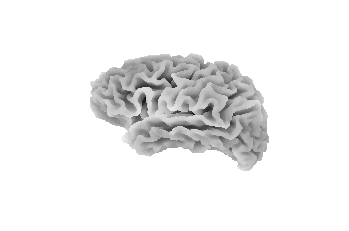

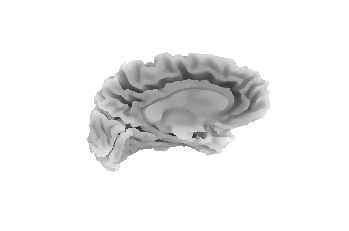

In [31]:
_ = nl.plotting.plot_surf('lh.white', bg_map=sulc, view='lateral')
_ = nl.plotting.plot_surf('lh.white', bg_map=sulc, view='medial')

Looks reasonable. Let's overlay it with the `aparc` parcellation. Nilearn doesn't handle these well yet, so again, we'll load with nibabel.

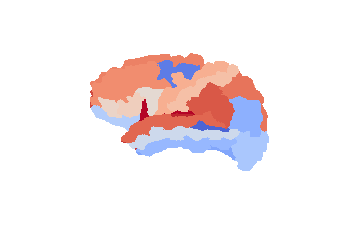

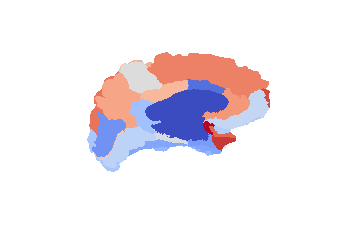

In [32]:
aparc = nib.freesurfer.read_annot('example/derivatives/freesurfer/sub-01/label/lh.aparc.annot')

_ = nl.plotting.plot_surf_roi('lh.white', aparc[0], bg_map=sulc, view='lateral')
_ = nl.plotting.plot_surf_roi('lh.white', aparc[0], bg_map=sulc, view='medial')

----------

## Machine learning in nilearn

Although nilearn's visualizations are quite nice, its primary purpose was to make running machine learning algorithms on neuroimaging data as simple as possible. In this sense, it is a bridge between nibabel and [scikit-learn](http://scikit-learn.org/stable/). On the one hand, it reformats images to be easily passed to scikit-learn, and on the other, it reformats the results in valid nibabel images.

This section is heavily based on the [nilearn decoding tutorial](https://nilearn.github.io/auto_examples/plot_decoding_tutorial.html).

The dataset should be pre-loaded for you on your docker image. Go ahead and verify:

In [33]:
import nilearn.datasets
import nilearn.input_data
haxby_dataset = nl.datasets.fetch_haxby()

bold = haxby_dataset.func[0]
mask = haxby_dataset.mask_vt[0]
anat = haxby_dataset.anat[0]
labels = haxby_dataset.session_target[0]

!nib-ls $bold

/home/jovyan/nilearn_data/haxby2001/subj2/bold.nii.gz int16 [ 40,  64,  64, 1452] 3.50x3.75x3.75x2.50   sform



We need our functional data in a 2D, sample `x` voxel matrix. To get that, we'll select a set of voxels in VT defined by `mask`.

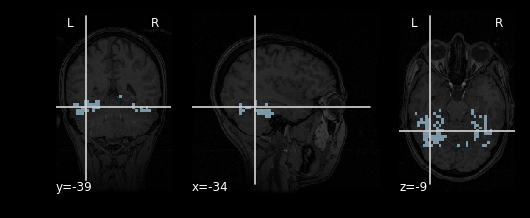

In [34]:
nl.plotting.plot_roi(mask, anat, cmap='Paired')

`NiftiMasker` is an object that applies a mask to a dataset and returns the masked voxels as a vector at each time point.
`standardize=True` z-scores each voxel.

In [35]:
masker = nl.input_data.NiftiMasker(mask_img=mask, standardize=True)
samples = masker.fit_transform(bold)
print(samples)
print(samples.shape)

[[  7.67579138e-01   2.31087089e+00  -2.05194458e-01 ...,  -1.02611411e+00
    8.79935026e-02   2.07205296e+00]
 [  5.56408286e-01   1.68334424e+00  -2.46449396e-01 ...,  -7.02380955e-01
   -3.45700502e-01   2.03410125e+00]
 [  7.67579138e-01   1.91866672e+00   1.08022266e-03 ...,  -9.93740857e-01
   -2.76309460e-01   2.14795637e+00]
 ..., 
 [ -4.29055721e-01  -1.68961132e+00  -7.41508603e-01 ...,  -1.54408729e+00
    1.80542183e+00  -1.67097285e-01]
 [ -1.47494584e-01  -1.80727255e+00  -2.46449396e-01 ...,  -1.77070057e+00
    1.54520547e+00   7.81695187e-01]
 [ -2.17884883e-01  -1.45428872e+00   1.08022266e-03 ...,  -1.64120734e+00
    1.26764119e+00   8.95550311e-01]]
(1452, 464)


To recover the original data shape (giving us a masked and z-scored BOLD series), we simply use the masker's inverse transform:

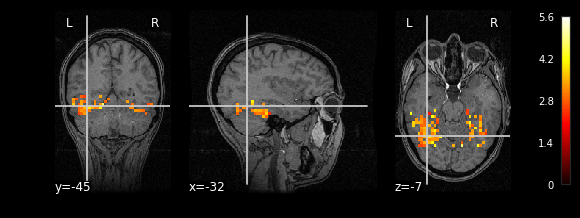

In [36]:
masked_epi = masker.inverse_transform(samples)

# For visualization... not useful
max_zscores = nl.image.math_img("np.abs(img).max(axis=3)", img=masked_epi)
nl.plotting.plot_stat_map(max_zscores, bg_img=anat, dim=-1)

In [58]:
attrs = np.recfromcsv(labels, delimiter=" ")
targets, chunks = attrs['labels'], attrs['chunks']
print(attrs.shape)
np.unique(attrs)

(1452,)


rec.array([('bottle',  0), ('bottle',  1), ('bottle',  2), ('bottle',  3),
 ('bottle',  4), ('bottle',  5), ('bottle',  6), ('bottle',  7),
 ('bottle',  8), ('bottle',  9), ('bottle', 10), ('bottle', 11),
 ('cat',  0), ('cat',  1), ('cat',  2), ('cat',  3), ('cat',  4),
 ('cat',  5), ('cat',  6), ('cat',  7), ('cat',  8), ('cat',  9),
 ('cat', 10), ('cat', 11), ('chair',  0), ('chair',  1), ('chair',  2),
 ('chair',  3), ('chair',  4), ('chair',  5), ('chair',  6), ('chair',  7),
 ('chair',  8), ('chair',  9), ('chair', 10), ('chair', 11), ('face',  0),
 ('face',  1), ('face',  2), ('face',  3), ('face',  4), ('face',  5),
 ('face',  6), ('face',  7), ('face',  8), ('face',  9), ('face', 10),
 ('face', 11), ('house',  0), ('house',  1), ('house',  2), ('house',  3),
 ('house',  4), ('house',  5), ('house',  6), ('house',  7), ('house',  8),
 ('house',  9), ('house', 10), ('house', 11), ('rest',  0), ('rest',  1),
 ('rest',  2), ('rest',  3), ('rest',  4), ('rest',  5), ('rest',  6),
 (